# Group 3: Fine-tuned DistilBERT on MRPC

**Owner:** Tim McGowan

This notebook fine-tunes `distilbert-base-uncased` to decide whether two sentences are paraphrases. It trains on 100, 250, 500, 1000, 2000 and all 3,668 training pairs (3 seeds each) to build the learning curve for our research question.

**Works in two places:**
- **Colab (GPU):** for the real runs. The first cell clones our GitHub repo.
- **Locally (PyCharm / Jupyter):** for checking the code. Without a GPU it runs a short "quick test" automatically.

**Rules from the proposal:** use the published splits as-is, make every tuning decision on **validation**, and use **test** only for the final comparison.

**Outputs** (all under `results/group3_distilbert/`):
- `runs.csv`: one row per run (size, seed, accuracy, F1, time)
- `predictions/`: probabilities for every validation and test pair, keyed by `idx` (needed for stacking and the Group 3 vs 4 error table)
- `learning_curve.png` and `summary.csv`

## 1. Find the project (clone it if we're in Colab)

In [1]:
# ━━━ CELL 1: FIND THE PROJECT (CLONE IT IF WE'RE IN COLAB) ━━━
import os
import sys
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/freemanchamjames/nlp_paraphrase_detection.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    PROJECT_ROOT = Path("/content/nlp_paraphrase_detection")
    if PROJECT_ROOT.exists():
        # Already cloned earlier in this session: get the latest from GitHub
        subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--rebase"], check=True)
    else:
        subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True)
else:
    # Local run: walk up from this notebook's folder until we find data/raw
    PROJECT_ROOT = Path.cwd().resolve()
    while not (PROJECT_ROOT / "data" / "raw").exists():
        if PROJECT_ROOT == PROJECT_ROOT.parent:
            raise FileNotFoundError("Couldn't find the repo. Open this notebook from inside the project folder.")
        PROJECT_ROOT = PROJECT_ROOT.parent

print("Running in Colab:", IN_COLAB)
print("Project root:    ", PROJECT_ROOT)

Running in Colab: False
Project root:     C:\Users\tbm09\PycharmProjects\nlp_paraphrase_detection


## 2. Imports and hardware check

If this cell says `No module named ...` locally, run `pip install -r requirements.txt` in the PyCharm terminal. Colab already has everything.

In Colab, turn on the GPU first: **Runtime → Change runtime type → T4 GPU**.

In [2]:
# ━━━ CELL 2: IMPORTS AND HARDWARE CHECK ━━━
import json
import time
import shutil
import tempfile
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)
import transformers

warnings.filterwarnings("ignore", category=FutureWarning)

# Shared team settings from src/config.py
sys.path.append(str(PROJECT_ROOT))
from src.config import SEEDS as SHARED_SEEDS, THRESHOLD, EXPECTED_COUNTS, evaluate

HAS_GPU = torch.cuda.is_available()
print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (CPU only)")

torch 2.14.1+cu132 | transformers 5.20.2
GPU: NVIDIA GeForce RTX 5090 Laptop GPU


## 3. Settings

Everything you might change lives here.

- `QUICK_TEST` is on automatically when there's no GPU. It trains one tiny run (100 pairs, 1 epoch) to prove the code works, and saves to a separate `_quick_test` folder so it never mixes with real results.
- Smaller training sets get more epochs, since 100 pairs is only about 7 batches per epoch. Early stopping ends a run once validation F1 stops improving.

In [3]:
# ━━━ CELL 3: SETTINGS ━━━
MODEL_NAME    = "distilbert-base-uncased"
MAX_LENGTH    = 128      # MRPC pairs are short; 128 tokens covers almost all of them
LEARNING_RATE = 2e-5
BATCH_SIZE    = 16
WEIGHT_DECAY  = 0.01
WARMUP_RATIO  = 0.1
PATIENCE      = 3        # epochs with no validation-F1 gain before stopping

TRAIN_SIZES = [100, 250, 500, 1000, 2000, "full"]
SEEDS       = list(SHARED_SEEDS)   # from src/config.py

def max_epochs_for(n_pairs):
    if n_pairs <= 250:
        return 20
    if n_pairs <= 1000:
        return 10
    return 5

QUICK_TEST = not HAS_GPU   # set to False to force full runs (slow on CPU)

if QUICK_TEST:
    TRAIN_SIZES = [100]
    SEEDS = [42]
    max_epochs_for = lambda n_pairs: 1
    OUT_DIR = PROJECT_ROOT / "results" / "group3_distilbert" / "_quick_test"
else:
    OUT_DIR = PROJECT_ROOT / "results" / "group3_distilbert"

PRED_DIR = OUT_DIR / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)
RUNS_CSV = OUT_DIR / "runs.csv"

# Checkpoints are big (~250 MB each), so they go to a temp folder outside the repo
CKPT_ROOT = Path(tempfile.gettempdir()) / "group3_checkpoints"

print("QUICK_TEST:", QUICK_TEST)
print("Saving results to:", OUT_DIR)



QUICK_TEST: False
Saving results to: C:\Users\tbm09\PycharmProjects\nlp_paraphrase_detection\results\group3_distilbert


## 4. Load the shared data from the repo

These are the CSVs made by `data/prepare_mrpc.py` (the published GLUE splits, untouched).

We check row counts and label counts instead of the SHA-256 values in `metadata.json`. Those hashes were made on Windows, where lines end in `\r\n`. Git stores the files with plain `\n` endings, so on Colab or a Mac the hashes won't match even though the data is identical.

In [4]:
# ━━━ CELL 4: LOAD THE SHARED DATA FROM THE REPO ━━━
RAW_DIR = PROJECT_ROOT / "data" / "raw"
train_df = pd.read_csv(RAW_DIR / "train.csv")
val_df   = pd.read_csv(RAW_DIR / "validation.csv")
test_df  = pd.read_csv(RAW_DIR / "test.csv")

# Expected (rows, label-1 count, label-0 count) for the published MRPC splits
EXPECTED =  EXPECTED_COUNTS   # from src/config.py

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    got = (len(df), int((df.label == 1).sum()), int((df.label == 0).sum()))
    status = "OK" if got == EXPECTED[name] else f"MISMATCH, expected {EXPECTED[name]}"
    print(f"{name:10s} rows={got[0]:5d}  paraphrase={got[1]:5d}  not={got[2]:5d}  "
          f"({got[1] / got[0]:.1%} paraphrase)  {status}")
    assert got == EXPECTED[name], f"{name} doesn't match the published split"

train      rows= 3668  paraphrase= 2474  not= 1194  (67.4% paraphrase)  OK
validation rows=  408  paraphrase=  279  not=  129  (68.4% paraphrase)  OK
test       rows= 1725  paraphrase= 1147  not=  578  (66.5% paraphrase)  OK


## 5. How DistilBERT sees a sentence pair

Both sentences go in together as `[CLS] sentence1 [SEP] sentence2 [SEP]`. Because they share one input, attention can compare words across the two sentences in every layer. That's Group 3's answer to the proposal's question, "where do the two sentences meet?"

MRPC text has extra spaces around punctuation (`Dominick 's`, `$ 2.5`). We **don't** clean it for Group 3, because DistilBERT's own tokenizer splits punctuation anyway (the proposal says the transformer uses its own tokenizer).

In [5]:
# ━━━ CELL 5: HOW DISTILBERT SEES A SENTENCE PAIR ━━━
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = train_df.iloc[1]
enc = tokenizer(example.sentence1, example.sentence2)
print("Sentence 1:", example.sentence1)
print("Sentence 2:", example.sentence2)
print("Label:", example.label)
print("\nWhat the model sees:")
print(tokenizer.convert_ids_to_tokens(enc["input_ids"]))

# How many pairs would be cut off at MAX_LENGTH?
lengths = [len(tokenizer(a, b)["input_ids"]) for a, b in zip(train_df.sentence1, train_df.sentence2)]
print(f"\nLongest pair: {max(lengths)} tokens | pairs over {MAX_LENGTH}: {sum(l > MAX_LENGTH for l in lengths)}")

Sentence 1: Yucaipa owned Dominick 's before selling the chain to Safeway in 1998 for $ 2.5 billion .
Sentence 2: Yucaipa bought Dominick 's in 1995 for $ 693 million and sold it to Safeway for $ 1.8 billion in 1998 .
Label: 0

What the model sees:
['[CLS]', 'yu', '##ca', '##ip', '##a', 'owned', 'dominic', '##k', "'", 's', 'before', 'selling', 'the', 'chain', 'to', 'safe', '##way', 'in', '1998', 'for', '$', '2', '.', '5', 'billion', '.', '[SEP]', 'yu', '##ca', '##ip', '##a', 'bought', 'dominic', '##k', "'", 's', 'in', '1995', 'for', '$', '69', '##3', 'million', 'and', 'sold', 'it', 'to', 'safe', '##way', 'for', '$', '1', '.', '8', 'billion', 'in', '1998', '.', '[SEP]']

Longest pair: 103 tokens | pairs over 128: 0


## 6. Helper functions

In [6]:
# ━━━ CELL 6: HELPER FUNCTIONS ━━━
def to_hf_dataset(df):
    """Turn a DataFrame into tokenized input the Trainer can use."""
    ds = Dataset.from_pandas(df[["sentence1", "sentence2", "label"]].reset_index(drop=True))
    return ds.map(
        lambda b: tokenizer(b["sentence1"], b["sentence2"], truncation=True, max_length=MAX_LENGTH),
        batched=True,
        remove_columns=["sentence1", "sentence2"],
    )

val_ds  = to_hf_dataset(val_df)
test_ds = to_hf_dataset(test_df)


def sample_train(n, seed):
    """Stratified sample: keeps the same ~68/32 label mix as the full training set."""
    if n == "full" or n >= len(train_df):
        return train_df
    subset, _ = train_test_split(train_df, train_size=n, stratify=train_df["label"], random_state=seed)
    return subset


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=-1)
    return evaluate(labels, preds)   # shared scoring from src/config.py


def predict_and_save(trainer, ds, df, split, n, seed):
    """Get P(paraphrase) for every pair and save it, keyed by idx."""
    logits = trainer.predict(ds).predictions
    probs = torch.softmax(torch.tensor(logits), dim=-1)[:, 1].numpy()
    preds = (probs >= THRESHOLD).astype(int)
    out = pd.DataFrame({"idx": df["idx"].values, "label": df["label"].values,
                        "prob_paraphrase": probs.round(6), "pred": preds})
    out.to_csv(PRED_DIR / f"{split}_n{n}_seed{seed}.csv", index=False)
    m = evaluate(out.label, out.pred)
    return m["accuracy"], m["f1"]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

## 7. One training run

`run_one(n, seed)` trains a fresh DistilBERT on `n` pairs, keeps the epoch with the best **validation F1**, then saves predictions for validation and test.

Test scores are recorded for the final comparison only. Don't use them to pick settings.

In [7]:
# ━━━ CELL 7: ONE TRAINING RUN ━━━
def run_one(n, seed):
    sub = sample_train(n, seed)
    n_pairs = len(sub)
    max_epochs = max_epochs_for(n_pairs)
    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    ckpt_dir = CKPT_ROOT / f"n{n_pairs}_seed{seed}"

    # Warmup = first 10% of all training steps (works on old and new transformers versions)
    total_steps = -(-n_pairs // BATCH_SIZE) * max_epochs
    warmup_steps = int(WARMUP_RATIO * total_steps)

    args = TrainingArguments(
        output_dir=str(ckpt_dir),
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=64,
        num_train_epochs=max_epochs,
        weight_decay=WEIGHT_DECAY,
        warmup_steps=warmup_steps,
        fp16=HAS_GPU,
        seed=seed,
        logging_strategy="epoch",
        report_to="none",
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=to_hf_dataset(sub),
        eval_dataset=val_ds,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
    )

    start = time.time()
    trainer.train()
    seconds = time.time() - start

    epochs_run = trainer.state.epoch
    best_epoch = None
    for entry in trainer.state.log_history:
        if "eval_f1" in entry and entry["eval_f1"] == trainer.state.best_metric:
            best_epoch = entry["epoch"]
            break

    val_acc, val_f1 = predict_and_save(trainer, val_ds, val_df, "validation", n_pairs, seed)
    test_acc, test_f1 = predict_and_save(trainer, test_ds, test_df, "test", n_pairs, seed)

    shutil.rmtree(ckpt_dir, ignore_errors=True)   # free disk space
    del trainer, model
    if HAS_GPU:
        torch.cuda.empty_cache()

    return {
        "n_train": n_pairs, "seed": seed,
        "epochs_run": round(float(epochs_run), 2),
        "best_epoch": best_epoch, "max_epochs": max_epochs,
        "val_accuracy": round(val_acc, 4), "val_f1": round(val_f1, 4),
        "test_accuracy": round(test_acc, 4), "test_f1": round(test_f1, 4),
        "train_seconds": round(seconds, 1),
        "model": MODEL_NAME, "lr": LEARNING_RATE, "batch_size": BATCH_SIZE,
        "finished_at": datetime.now().isoformat(timespec="seconds"),
    }

## 8. Run the learning curve

This cell **picks up where it left off**. Any (size, seed) already in `runs.csv` is skipped, so if Colab disconnects you can rerun it after pulling the latest results from GitHub.

Rough time on a Colab T4: about 30–45 minutes for all 18 runs.

In [8]:
# ━━━ CELL 8: RUN THE LEARNING CURVE ━━━
runs = pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame()
done = set(zip(runs.get("n_train", []), runs.get("seed", [])))

for n in TRAIN_SIZES:
    n_pairs = len(train_df) if n == "full" else n
    for seed in SEEDS:
        if (n_pairs, seed) in done:
            print(f"skip  n={n_pairs:5d} seed={seed} (already in runs.csv)")
            continue
        print(f"\n=== training n={n_pairs} seed={seed} ===")
        result = run_one(n, seed)
        runs = pd.concat([runs, pd.DataFrame([result])], ignore_index=True)
        runs.to_csv(RUNS_CSV, index=False)   # save after every run
        print(f"done  val F1={result['val_f1']:.3f}  test F1={result['test_f1']:.3f}  "
              f"({result['train_seconds']:.0f}s)")

runs

skip  n=  100 seed=42 (already in runs.csv)
skip  n=  100 seed=43 (already in runs.csv)
skip  n=  100 seed=44 (already in runs.csv)
skip  n=  250 seed=42 (already in runs.csv)
skip  n=  250 seed=43 (already in runs.csv)
skip  n=  250 seed=44 (already in runs.csv)
skip  n=  500 seed=42 (already in runs.csv)
skip  n=  500 seed=43 (already in runs.csv)
skip  n=  500 seed=44 (already in runs.csv)
skip  n= 1000 seed=42 (already in runs.csv)
skip  n= 1000 seed=43 (already in runs.csv)
skip  n= 1000 seed=44 (already in runs.csv)
skip  n= 2000 seed=42 (already in runs.csv)
skip  n= 2000 seed=43 (already in runs.csv)
skip  n= 2000 seed=44 (already in runs.csv)
skip  n= 3668 seed=42 (already in runs.csv)
skip  n= 3668 seed=43 (already in runs.csv)
skip  n= 3668 seed=44 (already in runs.csv)


,n_train,seed,epochs_run,best_epoch,max_epochs,val_accuracy,val_f1,test_accuracy,test_f1,train_seconds,model,lr,batch_size,finished_at
0,3668,42,5.0,4.0,5,0.8456,0.8927,0.8278,0.8763,163.4,distilbert-base-uncased,0.00002,16,2026-10-13T18:54:44
1,100,42,5.0,2.0,20,0.6838,0.8122,0.6649,0.7987,153.3,distilbert-base-uncased,0.00002,16,2026-10-13T19:45:44
2,100,43,5.0,2.0,20,0.6838,0.8122,0.6649,0.7987,89.6,distilbert-base-uncased,0.00002,16,2026-10-13T19:47:16
3,100,44,5.0,2.0,20,0.6838,0.8122,0.6649,0.7987,28.3,distilbert-base-uncased,0.00002,16,2026-10-13T19:47:47
4,250,42,6.0,3.0,20,0.6961,0.8160,0.6800,0.8029,41.0,distilbert-base-uncased,0.00002,16,2026-10-13T19:48:30
5,250,43,10.0,7.0,20,0.7328,0.8305,0.6829,0.7921,79.4,distilbert-base-uncased,0.00002,16,2026-10-13T19:49:52
6,250,44,7.0,4.0,20,0.7034,0.8202,0.6864,0.8062,59.9,distilbert-base-uncased,0.00002,16,2026-10-13T19:50:54
7,500,42,10.0,7.0,10,0.7623,0.8448,0.7316,0.8188,153.5,distilbert-base-uncased,0.00002,16,2026-10-13T19:53:31
8,500,43,10.0,10.0,10,0.7794,0.8505,0.7409,0.8164,107.4,distilbert-base-uncased,0.00002,16,2026-10-13T19:55:22
9,500,44,10.0,8.0,10,0.7941,0.8586,0.7478,0.8209,142.7,distilbert-base-uncased,0.00002,16,2026-10-13T19:57:47


## 9. Summary table and learning curve

The mean and standard deviation across seeds for each training size. The shaded band shows how much results move between seeds. When two points' bands overlap, the difference may just be noise.

Once Group 4 has Qwen's test F1 scores, enter them below and they'll show up as horizontal lines. Where the DistilBERT curve crosses them is the answer to our research question.

,n_train,runs,val_f1_mean,val_f1_std,test_f1_mean,test_f1_std,test_acc_mean
0,100,3,0.8122,0.0000,0.7987,0.0000,0.6649
1,250,3,0.8222,0.0075,0.8004,0.0074,0.6831
2,500,3,0.8513,0.0069,0.8187,0.0023,0.7401
3,1000,3,0.8710,0.0040,0.8426,0.0087,0.7766
4,2000,3,0.8954,0.0043,0.8638,0.0076,0.8124
5,3668,3,0.8939,0.0011,0.8741,0.0020,0.8259


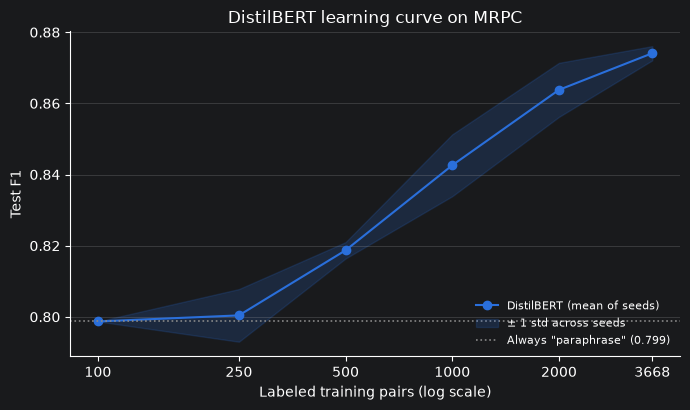

In [9]:
# ━━━ CELL 9: SUMMARY TABLE AND LEARNING CURVE ━━━
QWEN_ZERO_SHOT_TEST_F1 = None   # e.g. 0.78, from Group 4
QWEN_FEW_SHOT_TEST_F1  = None

runs = pd.read_csv(RUNS_CSV)
summary = (runs.groupby("n_train")
               .agg(runs=("seed", "count"),
                    val_f1_mean=("val_f1", "mean"), val_f1_std=("val_f1", "std"),
                    test_f1_mean=("test_f1", "mean"), test_f1_std=("test_f1", "std"),
                    test_acc_mean=("test_accuracy", "mean"))
               .round(4).reset_index())
summary.to_csv(OUT_DIR / "summary.csv", index=False)
display(summary)

# Baseline to beat: always guessing "paraphrase"
always_yes_f1 = f1_score(test_df.label, np.ones(len(test_df), dtype=int))

fig, ax = plt.subplots(figsize=(7, 4.2))
x = summary.n_train
mean, std = summary.test_f1_mean, summary.test_f1_std.fillna(0)
ax.plot(x, mean, marker="o", color="#2a6fdb", label="DistilBERT (mean of seeds)")
ax.fill_between(x, mean - std, mean + std, color="#2a6fdb", alpha=0.18, label="± 1 std across seeds")
ax.axhline(always_yes_f1, color="#888888", ls=":", lw=1.2, label=f'Always "paraphrase" ({always_yes_f1:.3f})')
if QWEN_ZERO_SHOT_TEST_F1 is not None:
    ax.axhline(QWEN_ZERO_SHOT_TEST_F1, color="#d1495b", ls="--", lw=1.4, label="Qwen zero-shot")
if QWEN_FEW_SHOT_TEST_F1 is not None:
    ax.axhline(QWEN_FEW_SHOT_TEST_F1, color="#e8873a", ls="--", lw=1.4, label="Qwen few-shot")
ax.set_xscale("log")
ax.set_xticks(list(x))
ax.set_xticklabels([str(v) for v in x])
ax.minorticks_off()
ax.set_xlabel("Labeled training pairs (log scale)")
ax.set_ylabel("Test F1")
ax.set_title("DistilBERT learning curve on MRPC")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(OUT_DIR / "learning_curve.png", dpi=150)
plt.show()

## 10. Small-size tuning

Retrains the two smallest sizes (100 and 250 pairs) with bigger learning rates and more patience, to check whether the poor results there come from the settings or from too little data. Choices are made on **validation** only. Results go to `results/group3_distilbert/tuning_small/`, so the main 18 runs are never touched.

In [10]:
# ━━━ CELL 10: SMALL-SIZE TUNING ━━━
TUNE_DIR      = PROJECT_ROOT / "results" / "group3_distilbert" / "tuning_small"
TUNE_CSV      = TUNE_DIR / "tuning_runs.csv"
TUNE_SIZES    = [100, 250]
TUNE_LRS      = [5e-5, 1e-4]
TUNE_PATIENCE = 5

TUNE_DIR.mkdir(parents=True, exist_ok=True)
tune = pd.read_csv(TUNE_CSV) if TUNE_CSV.exists() else pd.DataFrame()
done = set(zip(tune.get("n_train", []), tune.get("seed", []), tune.get("lr", [])))

saved = (LEARNING_RATE, PATIENCE, PRED_DIR)      # restore the main settings afterwards
try:
    PATIENCE = TUNE_PATIENCE
    for n in TUNE_SIZES:
        for lr in TUNE_LRS:
            LEARNING_RATE = lr
            PRED_DIR = TUNE_DIR / f"predictions_lr{lr:g}"
            PRED_DIR.mkdir(parents=True, exist_ok=True)
            for seed in SEEDS:
                if (n, seed, lr) in done:
                    print(f"skip  n={n} lr={lr:g} seed={seed}")
                    continue
                print(f"\n=== tuning n={n} lr={lr:g} seed={seed} ===")
                result = run_one(n, seed)
                result["patience"] = PATIENCE
                tune = pd.concat([tune, pd.DataFrame([result])], ignore_index=True)
                tune.to_csv(TUNE_CSV, index=False)          # save after every run
                print(f"done  val F1={result['val_f1']:.3f}  test F1={result['test_f1']:.3f}  "
                      f"({result['train_seconds']:.0f}s)")
finally:
    LEARNING_RATE, PATIENCE, PRED_DIR = saved

skip  n=100 lr=5e-05 seed=42
skip  n=100 lr=5e-05 seed=43
skip  n=100 lr=5e-05 seed=44
skip  n=100 lr=0.0001 seed=42
skip  n=100 lr=0.0001 seed=43
skip  n=100 lr=0.0001 seed=44
skip  n=250 lr=5e-05 seed=42
skip  n=250 lr=5e-05 seed=43
skip  n=250 lr=5e-05 seed=44
skip  n=250 lr=0.0001 seed=42
skip  n=250 lr=0.0001 seed=43
skip  n=250 lr=0.0001 seed=44


## 11. Compare default vs tuned settings

Puts the original runs and the tuning runs side by side. `said_yes` = how often the model answered "paraphrase" on test (1.0 means it said yes to everything).

In [11]:
# ━━━ CELL 11: COMPARE DEFAULT VS TUNED SETTINGS ━━━
def share_yes(n, seed, lr, split="test"):
    """How often the model said 'paraphrase' (1.0 = it always said yes)."""
    folder = (PROJECT_ROOT / "results" / "group3_distilbert" / "predictions" if lr == 2e-5
              else TUNE_DIR / f"predictions_lr{lr:g}")
    return pd.read_csv(folder / f"{split}_n{n}_seed{seed}.csv")["pred"].mean()

base = pd.read_csv(RUNS_CSV)
base = base[base.n_train.isin(TUNE_SIZES)].assign(patience=3)
both = pd.concat([base, pd.read_csv(TUNE_CSV)], ignore_index=True)
both["test_said_yes"] = [share_yes(r.n_train, r.seed, r.lr) for r in both.itertuples()]

table = (both.groupby(["n_train", "lr", "patience"])
             .agg(val_f1=("val_f1", "mean"), val_f1_sd=("val_f1", "std"),
                  test_f1=("test_f1", "mean"), test_f1_sd=("test_f1", "std"),
                  said_yes=("test_said_yes", "mean"))
             .round(3).reset_index())
table.to_csv(TUNE_DIR / "tuning_summary.csv", index=False)
display(table)

best = table.loc[table.groupby("n_train")["val_f1"].idxmax()]
print("Best setting per size, picked by VALIDATION F1 (test F1 is reported, not used to choose):")
display(best[["n_train", "lr", "patience", "val_f1", "test_f1", "said_yes"]])

,n_train,lr,patience,val_f1,val_f1_sd,test_f1,test_f1_sd,said_yes
0,100,0.00002,3,0.812,0.000,0.799,0.000,1.000
1,100,0.00005,5,0.818,0.005,0.799,0.003,0.954
2,100,0.00010,5,0.818,0.006,0.799,0.004,0.950
3,250,0.00002,3,0.822,0.007,0.800,0.007,0.924
4,250,0.00005,5,0.830,0.012,0.803,0.011,0.845
5,250,0.00010,5,0.821,0.007,0.803,0.005,0.927


Best setting per size, picked by VALIDATION F1 (test F1 is reported, not used to choose):


,n_train,lr,patience,val_f1,test_f1,said_yes
1,100,0.00005,5,0.818,0.799,0.954
4,250,0.00005,5,0.830,0.803,0.845


## 12. Save results to GitHub

The cell below **asks for your name** and saves a small record, `last_run.json`, in the results folder (who ran it, when, where, on which GPU), so the team can see who last ran the notebook. In Colab it also asks for your **GitHub email** and pushes the results under your name.

Only the small result files get committed (`runs.csv`, `summary.csv`, `predictions/`, `learning_curve.png`, `last_run.json`). Model weights stay out of the repo.

**Locally (PyCharm):** run the cell, then Git → Commit, tick `results/group3_distilbert`, and Commit and Push.

**In Colab, one-time setup:**
1. On GitHub: Settings → Developer settings → Personal access tokens → **Tokens (classic)** → Generate new token (classic), and tick the **`repo`** box.
2. In Colab: click the 🔑 **Secrets** icon in the left sidebar, add `GITHUB_TOKEN` with the token as its value, and turn on notebook access.

Never paste the token into the notebook itself.

In [12]:
# ━━━ CELL 12: SAVE RESULTS TO GITHUB ━━━
import json, platform
from datetime import datetime

if QUICK_TEST:
    print("Quick test: nothing to save or push.")
else:
    # Who ran this? Asked every time, so the record and the commit show the right person.
    RUN_BY = ""
    while not RUN_BY:
        RUN_BY = input("Your name (who ran this notebook): ").strip()

    record = {
        "run_by": RUN_BY,
        "finished_at": datetime.now().isoformat(timespec="seconds"),
        "where": "Colab" if IN_COLAB else f"local ({platform.node()})",
        "gpu": torch.cuda.get_device_name(0) if HAS_GPU else "CPU",
        "runs_in_runs_csv": len(pd.read_csv(RUNS_CSV)) if RUNS_CSV.exists() else 0,
    }
    (OUT_DIR / "last_run.json").write_text(json.dumps(record, indent=2))
    print("Saved", OUT_DIR / "last_run.json")
    print(json.dumps(record, indent=2))

    if IN_COLAB:
        RUN_EMAIL = ""
        while "@" not in RUN_EMAIL:
            RUN_EMAIL = input("Your GitHub email: ").strip()

        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        push_url = REPO_URL.replace("https://", f"https://x-access-token:{token}@")

        def git(*cmd):
            r = subprocess.run(["git", "-C", str(PROJECT_ROOT), *cmd], capture_output=True, text=True)
            print((r.stdout + r.stderr).replace(token, "***").strip())
            return r.returncode

        git("config", "user.name", RUN_BY)
        git("config", "user.email", RUN_EMAIL)
        git("add", "results/group3_distilbert")
        git("commit", "-m", f"Group 3: DistilBERT results ({record['runs_in_runs_csv']} runs), run by {RUN_BY}")
        git("pull", "--rebase", push_url, "main")
        if git("push", push_url, "HEAD:main") == 0:
            print("Pushed to GitHub.")
    else:
        print("\nLocal run: commit from PyCharm. Tick results/group3_distilbert (it includes last_run.json).")


Saved C:\Users\tbm09\PycharmProjects\nlp_paraphrase_detection\results\group3_distilbert\last_run.json
{
  "run_by": "Tim McGowan",
  "finished_at": "2026-10-21T13:14:09",
  "where": "local (Draconis)",
  "gpu": "NVIDIA GeForce RTX 5090 Laptop GPU",
  "runs_in_runs_csv": 18
}

Local run: commit from PyCharm. Tick results/group3_distilbert (it includes last_run.json).
